# Adım 1 — YOLO11n ile Pascal VOC Nesne Tespiti (Google Colab, T4 GPU)

**Önce:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU` seçin, sonra hücreleri sırayla çalıştırın.

| Hücre | İş |
|---|---|
| 1 | GPU kontrolü + kurulum |
| 2 | Google Drive bağlama + yollar (ağırlıklar Drive'a kaydedilir, oturum kopsa da kaybolmaz) |
| 3 | Pascal VOC 2007 + 2012 indirme |
| 4 | XML → YOLO formatı + **train / val / test** ayrımı |
| 5 | Veri seti istatistikleri |
| 6 | Hiperparametreler, optimizer, loss, aktivasyon (rapor için) |
| 7 | Eğitim (+ süre ölçümü) — kopma olursa **7b** ile devam |
| 8 | Toplam eğitim süresi + eğitim eğrileri |
| 9 | Test kümesinde mAP@50, mAP@50-95, Precision, Recall, F1 |
| 10 | IoU hesaplama |
| 11 | Tek görüntü inference süresi (GPU + CPU) |
| 12 | Örnek tahmin görselleri |
| 13 | Özet JSON + `best.pt` ve rapor dosyalarını indirme |

In [1]:
# ===== Hücre 1: GPU kontrolü ve kurulum =====
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q ultralytics

import torch, ultralytics, platform
print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("Ultralytics :", ultralytics.__version__)
print("CUDA        :", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU YOK!")
assert torch.cuda.is_available(), "GPU seçili değil: Çalışma zamanı → T4 GPU"

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python      : 3.13.16
PyTorch     : 2.14.1+cu130
Ultralytics : 8.4.218
CUDA        : True | NVIDIA L4


In [2]:
# ===== Hücre 2: Drive bağlama ve proje yolları =====
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
DRIVE_DIR   = Path('/content/drive/MyDrive/DL_HW_YOLO_VOC')   # kalıcı çıktılar (ağırlıklar, metrikler)
RUNS_DIR    = DRIVE_DIR / 'runs'
DL_DIR      = Path('/content/voc_raw')                         # ham zip'ler (geçici, Colab diski)
DATA_DIR    = Path('/content/datasets/VOC_split')              # YOLO formatlı, ayrılmış veri
RUN_NAME    = 'yolo11n_voc'
SEED        = 42

for p in (DRIVE_DIR, RUNS_DIR, DL_DIR, DATA_DIR):
    p.mkdir(parents=True, exist_ok=True)
print("Çıktılar Drive'da:", DRIVE_DIR)

Mounted at /content/drive
Çıktılar Drive'da: /content/drive/MyDrive/DL_HW_YOLO_VOC


In [3]:
# ===== Hücre 3: Pascal VOC 2007 + 2012 indirme (~3.6 GB, birkaç dakika) =====
import subprocess
BASE = 'https://github.com/ultralytics/assets/releases/download/v0.0.0'
ZIPS = ['VOCtrainval_06-Nov-2007.zip', 'VOCtest_06-Nov-2007.zip', 'VOCtrainval_11-May-2012.zip']

for z in ZIPS:
    zp = DL_DIR / z
    if not zp.exists():
        print('İndiriliyor:', z)
        subprocess.run(['wget', '-q', '-O', str(zp), f'{BASE}/{z}'], check=True)
    print('Açılıyor   :', z)
    subprocess.run(['unzip', '-q', '-o', str(zp), '-d', str(DL_DIR)], check=True)
    zp.unlink()   # disk yerini korumak için zip'i sil

VOC_ROOT = DL_DIR / 'VOCdevkit'
print(sorted(p.name for p in VOC_ROOT.iterdir()))   # beklenen: ['VOC2007', 'VOC2012']

İndiriliyor: VOCtrainval_06-Nov-2007.zip
Açılıyor   : VOCtrainval_06-Nov-2007.zip
İndiriliyor: VOCtest_06-Nov-2007.zip
Açılıyor   : VOCtest_06-Nov-2007.zip
İndiriliyor: VOCtrainval_11-May-2012.zip
Açılıyor   : VOCtrainval_11-May-2012.zip
['VOC2007', 'VOC2012']


In [4]:
# ===== Hücre 4: XML → YOLO etiketleri + train / val / test ayrımı =====
# Ayrım stratejisi (literatürle karşılaştırılabilir):
#   TEST  = VOC2007 test (resmi test kümesi, 4952 görüntü) — eğitimde HİÇ görülmez
#   TRAIN + VAL = VOC2007 trainval + VOC2012 trainval (16551 görüntü) → seed=42 ile %90 / %10 rastgele bölünür
# "difficult=1" olarak işaretli nesneler, VOC ve Ultralytics standardına uygun olarak etiketlere alınmaz.
import random, shutil, xml.etree.ElementTree as ET

CLASSES = ['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
           'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa',
           'train', 'tvmonitor']
CLS2ID = {c: i for i, c in enumerate(CLASSES)}
VAL_RATIO = 0.10

def read_ids(year, split):
    f = VOC_ROOT / f'VOC{year}' / 'ImageSets' / 'Main' / f'{split}.txt'
    return [(year, l.strip()) for l in f.read_text().splitlines() if l.strip()]

def xml_to_yolo(year, img_id):
    root = ET.parse(VOC_ROOT / f'VOC{year}' / 'Annotations' / f'{img_id}.xml').getroot()
    w, h = int(root.find('size/width').text), int(root.find('size/height').text)
    lines = []
    for obj in root.iter('object'):
        name = obj.find('name').text.strip()
        diff = obj.find('difficult')
        if name not in CLS2ID or (diff is not None and int(diff.text) == 1):
            continue
        b = obj.find('bndbox')
        x1, y1, x2, y2 = (float(b.find(k).text) for k in ('xmin', 'ymin', 'xmax', 'ymax'))
        # VOC koordinatları 1 tabanlı piksel → normalize (cx, cy, w, h)
        cx, cy = ((x1 + x2) / 2 - 1) / w, ((y1 + y2) / 2 - 1) / h
        bw, bh = (x2 - x1) / w, (y2 - y1) / h
        lines.append(f'{CLS2ID[name]} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}')
    return lines

trainval = read_ids('2007', 'trainval') + read_ids('2012', 'trainval')
test     = read_ids('2007', 'test')
random.Random(SEED).shuffle(trainval)
n_val  = int(len(trainval) * VAL_RATIO)
splits = {'train': trainval[n_val:], 'val': trainval[:n_val], 'test': test}

for split, items in splits.items():
    (DATA_DIR / 'images' / split).mkdir(parents=True, exist_ok=True)
    (DATA_DIR / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for year, img_id in items:
        stem = f'{year}_{img_id}'      # yıllar arası isim çakışmasını önler
        src = VOC_ROOT / f'VOC{year}' / 'JPEGImages' / f'{img_id}.jpg'
        dst = DATA_DIR / 'images' / split / f'{stem}.jpg'
        if not dst.exists():
            shutil.copy2(src, dst)
        (DATA_DIR / 'labels' / split / f'{stem}.txt').write_text('\n'.join(xml_to_yolo(year, img_id)))
    print(f'{split:5s}: {len(items):6d} görüntü')

# Ultralytics veri seti tanım dosyası
yaml_txt = f"path: {DATA_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
yaml_txt += ''.join(f'  {i}: {c}\n' for i, c in enumerate(CLASSES))
DATA_YAML = DATA_DIR / 'voc_split.yaml'
DATA_YAML.write_text(yaml_txt)
shutil.copy2(DATA_YAML, DRIVE_DIR / 'voc_split.yaml')
print(yaml_txt)

train:  14896 görüntü
val  :   1655 görüntü
test :   4952 görüntü
path: /content/datasets/VOC_split
train: images/train
val: images/val
test: images/test
names:
  0: aeroplane
  1: bicycle
  2: bird
  3: boat
  4: bottle
  5: bus
  6: car
  7: cat
  8: chair
  9: cow
  10: diningtable
  11: dog
  12: horse
  13: motorbike
  14: person
  15: pottedplant
  16: sheep
  17: sofa
  18: train
  19: tvmonitor



In [5]:
# ===== Hücre 5: Veri seti istatistikleri (rapor için) =====
import pandas as pd
from collections import Counter

stats = {}
for split in ('train', 'val', 'test'):
    cnt = Counter()
    for f in (DATA_DIR / 'labels' / split).glob('*.txt'):
        for line in f.read_text().splitlines():
            cnt[CLASSES[int(line.split()[0])]] += 1
    stats[split] = cnt
df_stats = pd.DataFrame(stats).reindex(CLASSES).fillna(0).astype(int)
df_stats.loc['TOPLAM nesne'] = df_stats.sum()
n_imgs = {s: len(list((DATA_DIR / 'images' / s).glob('*.jpg'))) for s in ('train', 'val', 'test')}
df_stats.loc['TOPLAM görüntü'] = [n_imgs[s] for s in df_stats.columns]
df_stats.to_csv(DRIVE_DIR / 'dataset_stats.csv')
display(df_stats)

,train,val,test
aeroplane,1041,130,285
bicycle,960,104,337
bird,1433,172,459
boat,1033,107,263
bottle,1578,186,469
bus,732,90,213
car,2921,346,1201
cat,1437,156,358
chair,2876,276,756
cow,763,84,244


In [13]:
# ===== Hücre 6: Model ve eğitim ayarları (rapordaki "Hyperparameters / Optimizer / Loss / Activation" alanları) =====
from ultralytics import YOLO
RUN_NAME = 'yolo11n_voc_v3'

MODEL_WEIGHTS = 'yolo11n.pt'   # COCO üzerinde ön-eğitimli YOLO11-nano → transfer learning

HYP = dict(
    epochs        = 40,
    imgsz         = 640,     # giriş boyutu 640x640 (YOLO standardı, letterbox ile)
    batch         = 32,      # T4 16 GB'a nano model için rahat sığar
    optimizer     = 'SGD',   # açıkça seçildi ('auto' yerine) → raporda net olsun
    lr0           = 0.002,    # başlangıç öğrenme oranı (SGD için YOLO varsayılanı)
    lrf           = 0.01,    # son lr = lr0 * lrf (lineer azalma)
    momentum      = 0.937,
    weight_decay  = 0.0005,  # L2 düzenlileştirme
    warmup_epochs = 3,       # ilk 3 epoch'ta lr kademeli artar (kararlı başlangıç)
    patience      = 0,
    box = 7.5, cls = 0.5, dfl = 1.5,   # loss bileşenlerinin ağırlıkları (Ultralytics varsayılanları)
    mosaic        = 1.0,     # veri artırma: mosaic
    close_mosaic  = 5,       # son 5 epoch mosaic kapalı (gerçek görüntü dağılımına ince ayar)
    fliplr        = 0.5,     # yatay çevirme
    amp           = True,    # karma hassasiyet (FP16) → T4'te hız
    seed          = SEED,
    deterministic = True,
    workers       = 8,
    cache         = False,   # 15k görüntü 12 GB RAM'e sığmaz
)

model = YOLO(MODEL_WEIGHTS)
model.info()   # katman sayısı, parametre sayısı, GFLOPs

print('\n--- Rapor için mimari bilgileri ---')
acts = sorted({type(m).__name__ for m in model.model.modules() if 'SiLU' in type(m).__name__ or 'ReLU' in type(m).__name__ or 'Sigmoid' in type(m).__name__})
print('Gizli katman aktivasyonu :', acts, '(SiLU)')
print('Çıkış fonksiyonu         : Sınıf skorları → Sigmoid (her sınıf bağımsız, çok-etiketli);')
print('                           Kutu → DFL (Distribution Focal Loss; dağılım üzerinde Softmax ile kutu kenarı beklenen değeri)')
print('Loss fonksiyonu          : L = 7.5·L_box(CIoU) + 0.5·L_cls(BCE) + 1.5·L_dfl(DFL)')
print('Head                     : Anchor-free, decoupled detection head; NMS ile son kutular')

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs

--- Rapor için mimari bilgileri ---
Gizli katman aktivasyonu : ['SiLU'] (SiLU)
Çıkış fonksiyonu         : Sınıf skorları → Sigmoid (her sınıf bağımsız, çok-etiketli);
                           Kutu → DFL (Distribution Focal Loss; dağılım üzerinde Softmax ile kutu kenarı beklenen değeri)
Loss fonksiyonu          : L = 7.5·L_box(CIoU) + 0.5·L_cls(BCE) + 1.5·L_dfl(DFL)
Head                     : Anchor-free, decoupled detection head; NMS ile son kutular


In [14]:
# ===== Hücre 7: EĞİTİM (süre otomatik ölçülür) =====
import time, json
t0 = time.time()
train_results = model.train(data=str(DATA_YAML), project=str(RUNS_DIR), name=RUN_NAME,
                            exist_ok=True, plots=True, **HYP)
session_train_sec = time.time() - t0

SAVE_DIR = Path(model.trainer.save_dir)
BEST_PT  = SAVE_DIR / 'weights' / 'best.pt'
print(f'\nBu oturumdaki eğitim süresi: {session_train_sec/3600:.2f} saat ({session_train_sec/60:.1f} dk)')
print('best.pt:', BEST_PT)
json.dump({'session_train_sec': session_train_sec}, open(SAVE_DIR / 'session_time.json', 'w'))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/VOC_split/voc_split.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_voc_v3, nbs=64, nms=None, opset=None, 

### Hücre 7b — Sadece oturum koparsa çalıştırın
Colab bağlantısı eğitim sırasında koparsa: **Hücre 1, 2, 3, 4'ü** tekrar çalıştırın (veri `/content` altında olduğu için silinir), ardından aşağıdaki hücreyi çalıştırın. Eğitim Drive'daki `last.pt`'den kaldığı epoch'tan devam eder. Toplam süre Hücre 8'de `results.csv` üzerinden doğru hesaplanır.

In [ ]:
# ===== Hücre 7b: Kopan eğitime devam et (gerekirse) =====
import time
from ultralytics import YOLO
LAST_PT = RUNS_DIR / RUN_NAME / 'weights' / 'last.pt'
model = YOLO(str(LAST_PT))
t0 = time.time()
model.train(resume=True)
print(f'Devam oturumu süresi: {(time.time()-t0)/60:.1f} dk')

Tamamlanan epoch      : 40
TOPLAM EĞİTİM SÜRESİ  : 0.78 saat = 47.0 dk   [results.csv (kümülatif, resume dahil)]
Epoch başına ortalama : 1.17 dk
En iyi epoch (val)    : 33  | val mAP50=0.8363  mAP50-95=0.6469


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
35,36,2542.32,0.74682,0.63446,1.08946,0.82092,0.75051,0.82705,0.63899,0.83924,0.75003,1.11316,0.000267,0.000267,0.000267
36,37,2611.56,0.73368,0.60014,1.07994,0.82208,0.74233,0.82808,0.63880,0.84033,0.74313,1.11554,0.000218,0.000218,0.000218
37,38,2681.11,0.72251,0.58846,1.07317,0.84440,0.73735,0.82876,0.63901,0.83896,0.73486,1.11629,0.000169,0.000169,0.000169
38,39,2750.45,0.71456,0.57446,1.06988,0.83482,0.74831,0.83080,0.63993,0.83786,0.73402,1.11626,0.000119,0.000119,0.000119
39,40,2819.97,0.70800,0.56801,1.06101,0.83980,0.74514,0.83179,0.64162,0.83784,0.73178,1.11711,0.000069,0.000069,0.000069


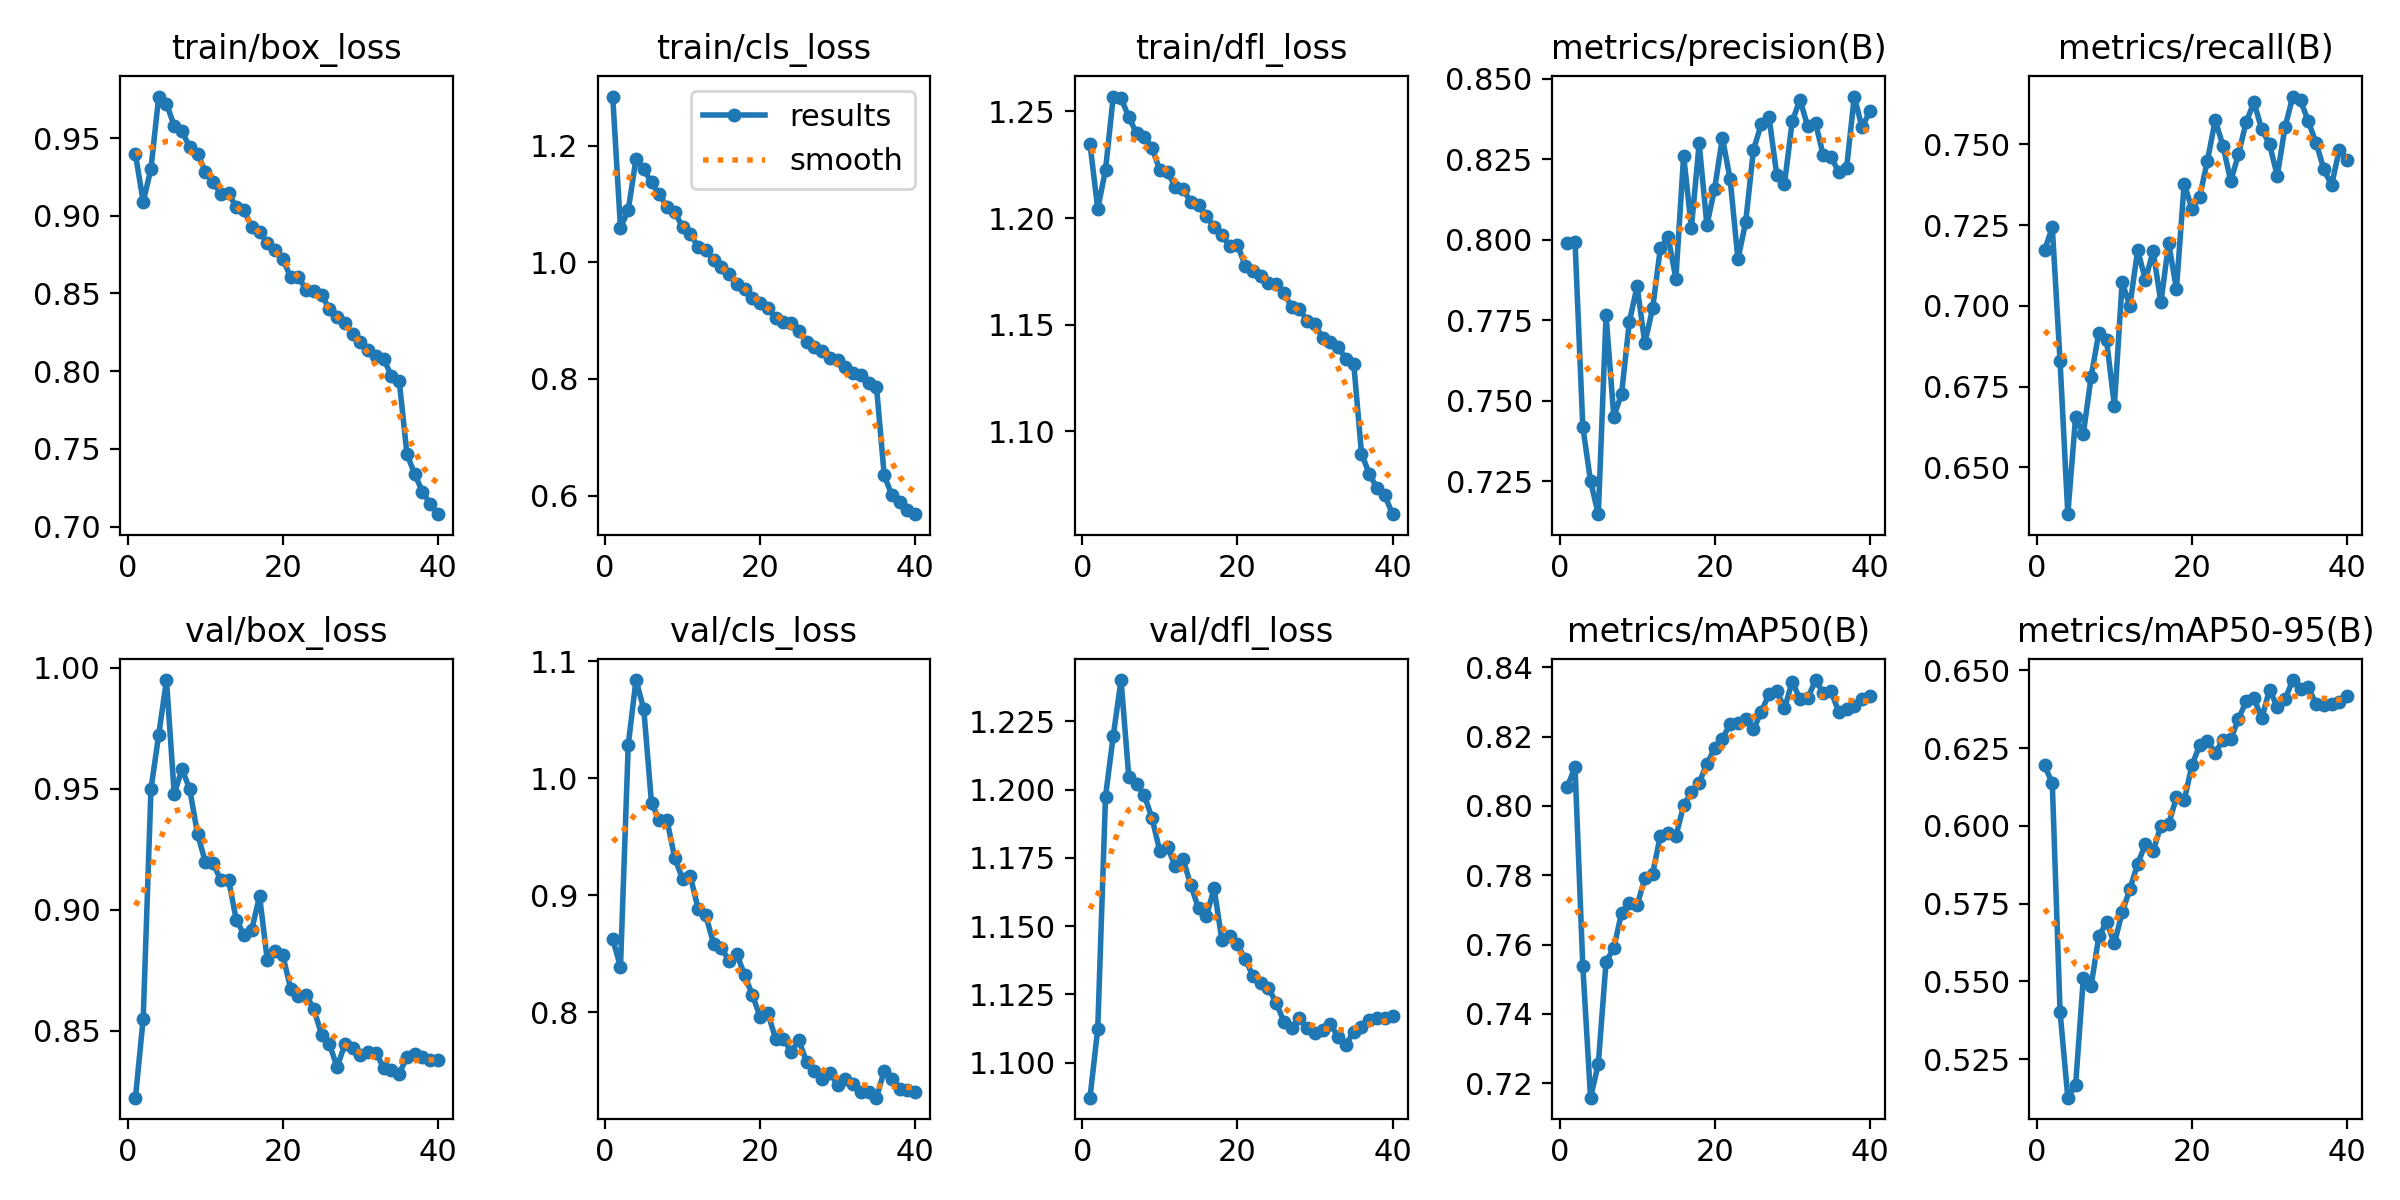

In [15]:
# ===== Hücre 8: Toplam eğitim süresi + eğitim eğrileri =====
import pandas as pd
from IPython.display import Image, display

SAVE_DIR = RUNS_DIR / RUN_NAME
BEST_PT  = SAVE_DIR / 'weights' / 'best.pt'
res = pd.read_csv(SAVE_DIR / 'results.csv')
res.columns = [c.strip() for c in res.columns]

if 'time' in res.columns:   # Ultralytics, devam edilen oturumlar dahil kümülatif süreyi tutar
    total_train_sec = float(res['time'].iloc[-1])
    src = 'results.csv (kümülatif, resume dahil)'
else:
    total_train_sec = json.load(open(SAVE_DIR / 'session_time.json'))['session_train_sec']
    src = 'Hücre 7 ölçümü'
epochs_done = len(res)
best_row = res.loc[res['metrics/mAP50-95(B)'].idxmax()]

print(f'Tamamlanan epoch      : {epochs_done}')
print(f'TOPLAM EĞİTİM SÜRESİ  : {total_train_sec/3600:.2f} saat = {total_train_sec/60:.1f} dk   [{src}]')
print(f'Epoch başına ortalama : {total_train_sec/epochs_done/60:.2f} dk')
print(f'En iyi epoch (val)    : {int(best_row["epoch"])}  | val mAP50={best_row["metrics/mAP50(B)"]:.4f}  mAP50-95={best_row["metrics/mAP50-95(B)"]:.4f}')
display(res.tail(5))
display(Image(filename=str(SAVE_DIR / 'results.png'), width=1000))

In [16]:
# ===== Hücre 9: TEST kümesinde değerlendirme (mAP@50, mAP@50-95, Precision, Recall, F1) =====
from ultralytics import YOLO
best_model = YOLO(str(BEST_PT))
test_metrics = best_model.val(data=str(DATA_YAML), split='test', imgsz=HYP['imgsz'], batch=32,
                              conf=0.001, iou=0.7, plots=True,
                              project=str(RUNS_DIR), name=RUN_NAME + '_test', exist_ok=True)
b = test_metrics.box
P, R = float(b.mp), float(b.mr)
F1 = 2 * P * R / (P + R + 1e-9)
print('\n========== TEST SONUÇLARI (VOC2007 test, 4952 görüntü) ==========')
print(f'mAP@50      : {b.map50:.4f}')
print(f'mAP@50-95   : {b.map:.4f}')
print(f'Precision   : {P:.4f}')
print(f'Recall      : {R:.4f}')
print(f'F1-score    : {F1:.4f}')
print('Hız (ms/görüntü, val batch):', {k: round(v, 2) for k, v in test_metrics.speed.items()})

per_class = pd.DataFrame({
    'class'    : [CLASSES[i] for i in b.ap_class_index],
    'AP@50'    : b.ap50,
    'AP@50-95' : b.ap,
}).sort_values('AP@50-95', ascending=False).reset_index(drop=True)
per_class.to_csv(DRIVE_DIR / 'test_per_class_ap.csv', index=False)
display(per_class.round(4))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11n summary (fused): 101 layers, 2,601,668 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2085.8±760.0 MB/s, size: 75.2 KB)
val: Scanning /content/datasets/VOC_split/labels/test... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 1.5Kit/s 3.4s
val: New cache created: /content/datasets/VOC_split/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 155/155 5.8it/s 26.6s
                   all       4952      12032      0.813      0.781      0.851       0.65
             aeroplane        204        285      0.923      0.828      0.909      0.701
               bicycle        239        337      0.895      0.831      0.923      0.727
                  bird        282        459      0.851      0.744      0.855      0.614
                  boat        172        263      0.73

,class,AP@50,AP@50-95
0,bus,0.9105,0.7936
1,car,0.9309,0.7558
2,horse,0.9413,0.7410
3,cat,0.8985,0.7372
4,bicycle,0.9230,0.7273
5,dog,0.8885,0.7235
6,train,0.9231,0.7068
7,aeroplane,0.9094,0.7013
8,sofa,0.8282,0.6807
9,motorbike,0.9171,0.6766


In [18]:
# ===== Hücre 10: IoU hesaplama (test kümesi) =====
# Ultralytics IoU'yu doğrudan raporlamaz; burada kendimiz hesaplıyoruz:
#  - Tahminler conf >= 0.25 ile alınır (Gradio uygulamasında kullanılacak eşik).
#  - Her görüntü ve sınıf için, güven skoruna göre sıralı tahminler, en yüksek IoU'lu eşleşmemiş GT ile açgözlü (greedy) eşleştirilir.
#  - Mean IoU (TP)      : IoU >= 0.5 ile eşleşen (doğru) tespitlerin ortalama IoU'su → konumlandırma kalitesi
#  - Mean best IoU (GT) : Her gerçek kutu için en iyi eşleşen tahminin IoU'su (kaçırılanlar 0) → genel kapsama
import numpy as np, torch
from ultralytics.utils.metrics import box_iou

CONF_APP, IOU_MATCH, BS = 0.25, 0.5, 32
test_imgs = sorted((DATA_DIR / 'images' / 'test').glob('*.jpg'))
torch.cuda.empty_cache()

def batched_predict(paths, bs=BS):
    # Görüntüleri 32'lik gruplar halinde modele verir (GPU belleği taşmasın diye)
    for i in range(0, len(paths), bs):
        yield from best_model.predict(source=[str(p) for p in paths[i:i + bs]], conf=CONF_APP,
                                      iou=0.7, imgsz=HYP['imgsz'], verbose=False)

def load_gt(img_path, w, h):
    lbl = DATA_DIR / 'labels' / 'test' / (img_path.stem + '.txt')
    rows = [list(map(float, l.split())) for l in lbl.read_text().splitlines() if l.strip()]
    if not rows:
        return torch.zeros((0, 4)), torch.zeros(0, dtype=torch.long)
    a = torch.tensor(rows)
    cx, cy, bw, bh = a[:, 1] * w, a[:, 2] * h, a[:, 3] * w, a[:, 4] * h
    return torch.stack([cx - bw/2, cy - bh/2, cx + bw/2, cy + bh/2], 1), a[:, 0].long()

tp_ious, gt_best_ious = [], []
n_pred = n_tp = n_gt = 0
for r in batched_predict(test_imgs):
    h, w = r.orig_shape
    gt_box, gt_cls = load_gt(Path(r.path), w, h)
    pb, pc, ps = r.boxes.xyxy.cpu(), r.boxes.cls.cpu().long(), r.boxes.conf.cpu()
    n_pred += len(pb); n_gt += len(gt_box)
    for c in torch.unique(torch.cat([gt_cls, pc])):
        g, p = gt_box[gt_cls == c], pb[pc == c]
        order = ps[pc == c].argsort(descending=True)
        p = p[order]
        if len(g) == 0:
            continue
        if len(p) == 0:
            gt_best_ious += [0.0] * len(g); continue
        iou = box_iou(p, g)                     # [n_pred_c, n_gt_c]
        gt_best_ious += iou.max(0).values.tolist()
        used = set()
        for i in range(len(p)):                 # greedy eşleştirme
            cand = [(iou[i, j].item(), j) for j in range(len(g)) if j not in used]
            if not cand: break
            best_iou, j = max(cand)
            if best_iou >= IOU_MATCH:
                used.add(j); tp_ious.append(best_iou); n_tp += 1

mean_iou_tp = float(np.mean(tp_ious)) if tp_ious else 0.0
mean_best_iou_gt = float(np.mean(gt_best_ious)) if gt_best_ious else 0.0
print(f'Tahmin sayısı (conf>={CONF_APP}) : {n_pred}  |  GT nesne sayısı: {n_gt}  |  TP (IoU>={IOU_MATCH}): {n_tp}')
print(f'Mean IoU (doğru tespitler)       : {mean_iou_tp:.4f}')
print(f'Mean best IoU (her GT için)      : {mean_best_iou_gt:.4f}')
print(f'Precision @conf={CONF_APP}          : {n_tp/max(n_pred,1):.4f}')
print(f'Recall    @conf={CONF_APP}          : {n_tp/max(n_gt,1):.4f}')

Tahmin sayısı (conf>=0.25) : 14539  |  GT nesne sayısı: 12032  |  TP (IoU>=0.5): 10285
Mean IoU (doğru tespitler)       : 0.8674
Mean best IoU (her GT için)      : 0.7645
Precision @conf=0.25          : 0.7074
Recall    @conf=0.25          : 0.8548


In [19]:
# ===== Hücre 11: Tek bir görüntü için inference süresi (GPU ve CPU) =====
import time, torch

def time_single_image(model, img, device, n_warmup=10, n_runs=100):
    for _ in range(n_warmup):
        model.predict(img, imgsz=HYP['imgsz'], conf=CONF_APP, device=device, verbose=False)
    total, inf_only = [], []
    for _ in range(n_runs):
        if device != 'cpu': torch.cuda.synchronize()
        t = time.perf_counter()
        r = model.predict(img, imgsz=HYP['imgsz'], conf=CONF_APP, device=device, verbose=False)[0]
        if device != 'cpu': torch.cuda.synchronize()
        total.append((time.perf_counter() - t) * 1000)
        inf_only.append(r.speed['inference'])
    return float(np.mean(total)), float(np.std(total)), float(np.mean(inf_only)), r.speed

sample_img = str(test_imgs[0])
gpu_total, gpu_std, gpu_inf, gpu_speed = time_single_image(best_model, sample_img, 0)
cpu_model = YOLO(str(BEST_PT))
cpu_total, cpu_std, cpu_inf, cpu_speed = time_single_image(cpu_model, sample_img, 'cpu', n_warmup=3, n_runs=20)

print(f'Görüntü: {Path(sample_img).name}, imgsz={HYP["imgsz"]}, batch=1')
print(f'GPU ({torch.cuda.get_device_name(0)}): uçtan uca {gpu_total:.2f} ± {gpu_std:.2f} ms  | sadece model {gpu_inf:.2f} ms  | ≈ {1000/gpu_total:.1f} FPS')
print(f'CPU (Colab, 2 vCPU)            : uçtan uca {cpu_total:.2f} ± {cpu_std:.2f} ms  | sadece model {cpu_inf:.2f} ms')
print('GPU ayrıntı (son çalıştırma, ms):', {k: round(v, 2) for k, v in gpu_speed.items()})

Görüntü: 2007_000001.jpg, imgsz=640, batch=1
GPU (NVIDIA L4): uçtan uca 14.15 ± 0.59 ms  | sadece model 9.42 ms  | ≈ 70.7 FPS
CPU (Colab, 2 vCPU)            : uçtan uca 39.35 ± 0.33 ms  | sadece model 34.89 ms
GPU ayrıntı (son çalıştırma, ms): {'preprocess': 1.3, 'inference': 9.55, 'postprocess': 1.32}


In [21]:
import os, torch
print("Toplam CPU çekirdeği :", os.cpu_count())
print("PyTorch thread sayısı:", torch.get_num_threads())
print("OMP_NUM_THREADS      :", os.environ.get("OMP_NUM_THREADS"))
!nproc --all

Toplam CPU çekirdeği : 12
PyTorch thread sayısı: 8
OMP_NUM_THREADS      : 1
12


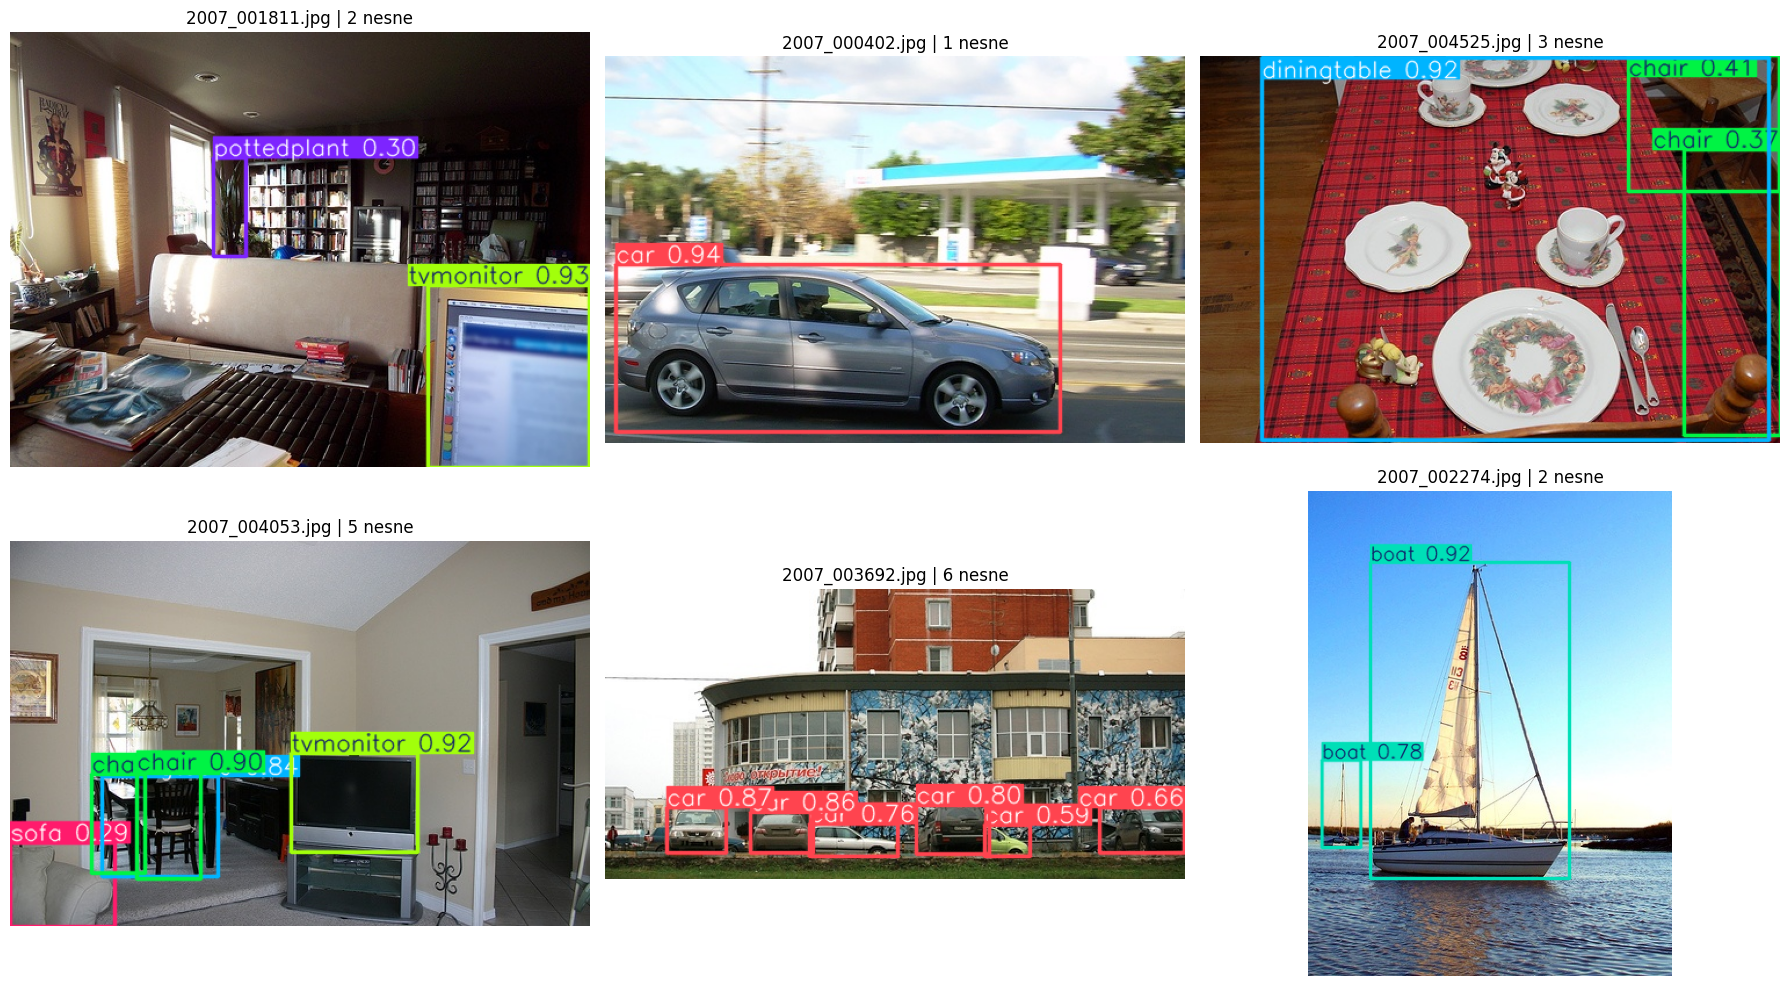

In [22]:
# ===== Hücre 12: Test kümesinden örnek tahminler (görsel kontrol) =====
import matplotlib.pyplot as plt
rng = random.Random(SEED)
samples = rng.sample(test_imgs, 6)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, p in zip(axes.ravel(), samples):
    r = best_model.predict(str(p), conf=CONF_APP, imgsz=HYP['imgsz'], verbose=False)[0]
    ax.imshow(r.plot()[:, :, ::-1]); ax.set_title(f'{p.name} | {len(r.boxes)} nesne'); ax.axis('off')
plt.tight_layout()
plt.savefig(DRIVE_DIR / 'test_samples.png', dpi=100)
plt.show()

In [23]:
# ===== Hücre 13: Özet kaydet + best.pt ve rapor dosyalarını indir =====
import json, shutil
from google.colab import files

summary = {
    'model': 'YOLO11n (COCO pretrained → Pascal VOC fine-tune)',
    'ultralytics_version': ultralytics.__version__,
    'torch_version': torch.__version__,
    'gpu': torch.cuda.get_device_name(0),
    'dataset_split_images': n_imgs,
    'hyperparameters': HYP,
    'epochs_completed': int(epochs_done),
    'best_epoch_val': int(best_row['epoch']),
    'total_train_time_min': round(total_train_sec / 60, 2),
    'test': {'mAP50': round(float(b.map50), 4), 'mAP50-95': round(float(b.map), 4),
             'precision': round(P, 4), 'recall': round(R, 4), 'f1': round(F1, 4),
             'mean_iou_tp@conf0.25': round(mean_iou_tp, 4),
             'mean_best_iou_per_gt@conf0.25': round(mean_best_iou_gt, 4)},
    'inference_ms_single_image': {'gpu_end_to_end': round(gpu_total, 2), 'gpu_model_only': round(gpu_inf, 2),
                                  'cpu_end_to_end': round(cpu_total, 2), 'cpu_model_only': round(cpu_inf, 2)},
}
(DRIVE_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

# best.pt'yi Drive köküne kopyala ve tarayıcıya indir
shutil.copy2(BEST_PT, DRIVE_DIR / 'best.pt')
files.download(str(DRIVE_DIR / 'best.pt'))

# Rapor için grafikler + metrik dosyaları tek zip
REPORT_DIR = Path('/content/report_assets'); REPORT_DIR.mkdir(exist_ok=True)
for f in list(SAVE_DIR.glob('*.png')) + list(SAVE_DIR.glob('*.csv')) + list(SAVE_DIR.glob('*.yaml')):
    shutil.copy2(f, REPORT_DIR / f'train_{f.name}')
for f in (RUNS_DIR / (RUN_NAME + '_test')).glob('*.png'):
    shutil.copy2(f, REPORT_DIR / f'test_{f.name}')
for f in ('summary.json', 'dataset_stats.csv', 'test_per_class_ap.csv', 'test_samples.png', 'voc_split.yaml'):
    shutil.copy2(DRIVE_DIR / f, REPORT_DIR / f)
shutil.make_archive('/content/report_assets', 'zip', REPORT_DIR)
files.download('/content/report_assets.zip')
print('İndirildi: best.pt ve report_assets.zip (aynı dosyalar Drive\'da da duruyor:', DRIVE_DIR, ')')

{
  "model": "YOLO11n (COCO pretrained → Pascal VOC fine-tune)",
  "ultralytics_version": "8.4.218",
  "torch_version": "2.14.1+cu130",
  "gpu": "NVIDIA L4",
  "dataset_split_images": {
    "train": 14896,
    "val": 1655,
    "test": 4952
  },
  "hyperparameters": {
    "epochs": 40,
    "imgsz": 640,
    "batch": 32,
    "optimizer": "SGD",
    "lr0": 0.002,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 3,
    "patience": 0,
    "box": 7.5,
    "cls": 0.5,
    "dfl": 1.5,
    "mosaic": 1.0,
    "close_mosaic": 5,
    "fliplr": 0.5,
    "amp": true,
    "seed": 42,
    "deterministic": true,
    "workers": 8,
    "cache": false
  },
  "epochs_completed": 40,
  "best_epoch_val": 33,
  "total_train_time_min": 47.0,
  "test": {
    "mAP50": 0.8507,
    "mAP50-95": 0.6501,
    "precision": 0.8129,
    "recall": 0.7813,
    "f1": 0.7968,
    "mean_iou_tp@conf0.25": 0.8674,
    "mean_best_iou_per_gt@conf0.25": 0.7645
  },
  "inference_ms_single_ima

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

İndirildi: best.pt ve report_assets.zip (aynı dosyalar Drive'da da duruyor: /content/drive/MyDrive/DL_HW_YOLO_VOC )
